# Analalyse de la distribution du vocabulaire

## Imports et dépendances

In [1]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/alperen/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## Créer une une liste de stopwords

In [2]:
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout", 
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu"]
sw = set(sw)

In [3]:
print(f"{len(sw)} stopwords:\n {sorted(sw)}")

197 stopwords:
 ['ai', 'aie', 'aient', 'aies', 'ainsi', 'ait', 'après', 'as', 'au', 'aura', 'aurai', 'auraient', 'aurais', 'aurait', 'auras', 'aurez', 'auriez', 'aurions', 'aurons', 'auront', 'aussi', 'autre', 'autres', 'aux', 'avaient', 'avais', 'avait', 'avec', 'avez', 'aviez', 'avions', 'avoir', 'avons', 'ayant', 'ayante', 'ayantes', 'ayants', 'ayez', 'ayons', 'bien', 'c', 'ce', 'cela', 'celle', 'ces', 'cet', 'cette', 'comme', 'contre', 'd', 'dans', 'de', 'depuis', 'des', 'deux', 'dire', 'dit', 'doit', 'donc', 'dont', 'du', 'elle', 'en', 'encore', 'entre', 'es', 'est', 'et', 'eu', 'eue', 'eues', 'eurent', 'eus', 'eusse', 'eussent', 'eusses', 'eussiez', 'eussions', 'eut', 'eux', 'eûmes', 'eût', 'eûtes', 'faire', 'fait', 'faut', 'furent', 'fus', 'fusse', 'fussent', 'fusses', 'fussiez', 'fussions', 'fut', 'fûmes', 'fût', 'fûtes', 'het', 'il', 'ils', 'j', 'je', 'jusqu', 'l', 'la', 'le', 'les', 'leur', 'lui', 'm', 'ma', 'mais', 'me', 'mes', 'moi', 'moins', 'mon', 'même', 'n', 'ne', 'non'

## Tokeniser

In [4]:
# Récupération du contenu du fichier
path = "../data/all.txt"
limit = 10**8

with open(path, 'r', encoding='utf-8') as f:
    text = f.read()[:limit]

In [5]:
# Tokenization
words = nltk.wordpunct_tokenize(text)
print(f"{len(words)} words found")

477052 words found


In [9]:
words[:100]

['plus',
 'grand',
 'soin',
 'd',
 "'",
 'éloigné',
 '**',
 'toute',
 'éventualité',
 'dangereuse',
 ',',
 'et',
 'comme',
 'l',
 "'",
 'opinion',
 'publique',
 'en',
 'Angleterre',
 'est',
 'surtout',
 'déslfçuse',
 'de',
 'la',
 'jîfliif',
 ',',
 'l',
 "'",
 'ofgilné',
 'ail',
 'n',
 '}',
 'inistSrë',
 'lie',
 'croit',
 'jiâs',
 'avoii1',
 'de',
 'plus',
 'sûr',
 'nloyeh',
 'ile',
 'ié',
 'servir',
 'que',
 'de',
 'faire',
 'croire',
 'que',
 'la',
 'paix',
 'ne',
 'sera',
 'pas',
 'troublée',
 '.',
 'Ce',
 'moyen',
 'serait',
 'excellent',
 ',',
 'si',
 'on',
 'pouvait',
 'ajouter',
 'foi',
 'aux',
 'asser',
 '\xad',
 'tions',
 'du',
 'Moiiiina',
 '-',
 'Post',
 ';',
 'mais',
 'il',
 'faut',
 'espérer',
 'que',
 'd',
 "'",
 'ici',
 'au',
 'jour',
 'du',
 'vote',
 'décisif',
 'le',
 'cabinet',
 'aura',
 'trouvé',
 'des',
 'points',
 'd',
 "'",
 'appUie',
 'plus',
 'solides',
 'que']

## Calculer la taille du vocabulaire

In [8]:
# Eliminer les stopwords et les termes non alphabétiques
kept = [w.lower() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
voc = set(kept)
print(f"{len(kept)} words kept ({len(voc)} different word forms)")

160086 words kept (53965 different word forms)


## Récupérer les mots les plus fréquents et en faire un plot

In [10]:
fdist = nltk.FreqDist(kept)
fdist.most_common(10)

[('rue', 558),
 ('ans', 328),
 ('dem', 291),
 ('bruxelles', 270),
 ('heures', 269),
 ('très', 267),
 ('prix', 261),
 ('peu', 237),
 ('ment', 235),
 ('grand', 224)]

<Axes: xlabel='Samples', ylabel='Cumulative Counts'>

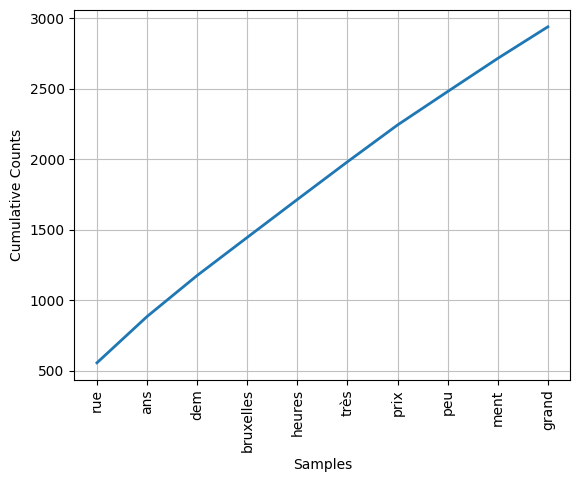

In [11]:
# Plot: les n mots les plus fréquents
n = 10
fdist.plot(n, cumulative=True)

## Détecter les Hapax (mots qui n'apparaissent qu'une fois dans le corpus)

In [12]:
fdist.hapaxes()[:30]

['déslfçuse',
 'jîfliif',
 'ofgilné',
 'inistsrë',
 'jiâs',
 'nloyeh',
 'moiiiina',
 'siiis',
 'testante',
 'ngleterre',
 'précéderont',
 'dévoiler',
 'îrlandnio',
 'parisdu',
 'iait',
 'basée',
 'sidérants',
 'assimilée',
 'confiscationu',
 'exproprié',
 'assimilé',
 'haussonville',
 'analogiiëi',
 'encouru',
 'signala',
 'périsse',
 'imprimons',
 'dàiis',
 'moining',
 'évidentes']

## Trouver les mots les plus longs du corpus

In [13]:
n = 30
sorted(voc, key=len, reverse=True)[:n]

['lllllllllllllllllllllllllllllllllllllillllllllllllllllllllllllllllllllllllllllh',
 'iiiiiiiiiiiiiiiiiiniiiiiiiiiiiiiiiiiiiiiii',
 'ulllllllllllllllllllllllllll',
 'elleavaitgracicusemenuccédé',
 'isonlattachésàdesarbresaux',
 'colorationlecharmantrôled',
 'domaineellesontrapidsment',
 'raffinerietirlemontoise',
 'marcinelleetcouilletsoo',
 'damneraàrendreleurscomp',
 'placômeqtabypouiéeaireâ',
 'iioiiielleaffirmaliijn',
 'candidatsconservateurs',
 'nrcineuietshiipleuienl',
 'fraîcheurparunesavante',
 'llllllllllllllllllllll',
 'trouvéexposésurlavoie',
 'etnombreusesadbésions',
 'enentendantretentirce',
 'ctmminutratlspfequête',
 'vousexclusivementàla',
 'enseignementprimaire',
 'srsfagaæaïbggabsgsbb',
 'éfofotahtatawtogmfen',
 'rapporteurreprocbcau',
 'sicilienhèfjvpèndant',
 'omniaiïperniatorrhh',
 'raitwaysvoieélroite',
 'chrqniquejudiciaire',
 'nouvellesjudicimres']